# Hands-On Lab - 20.11.2026

The following code has been adapted from the [H2020 MULTIPLY training ](https://github.com/multiply-org/H2020_MULTIPLY_training).
All credits for this work is to the authors.

<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#This-implementation-of-PROSAIL" data-toc-modified-id="This-implementation-of-PROSAIL-1"><span class="toc-item-num">1&nbsp;&nbsp;</span>This implementation of PROSAIL</a></span></li><li><span><a href="#Sensitivity-analysis" data-toc-modified-id="Sensitivity-analysis-2"><span class="toc-item-num">2&nbsp;&nbsp;</span>Sensitivity analysis</a></span></li><li><span><a href="#Angular-effects" data-toc-modified-id="Angular-effects-3"><span class="toc-item-num">3&nbsp;&nbsp;</span>Angular effects</a></span><ul class="toc-item"><li><span><a href="#Questions:" data-toc-modified-id="Questions:-3.1"><span class="toc-item-num">3.1&nbsp;&nbsp;</span>Questions:</a></span></li></ul></li><li><span><a href="#A-trip-to-RED/NIR-space" data-toc-modified-id="A-trip-to-RED/NIR-space-4"><span class="toc-item-num">4&nbsp;&nbsp;</span>A trip to RED/NIR space</a></span></li><li><span><a href="#So-what-have-we-learned?" data-toc-modified-id="So-what-have-we-learned?-6"><span class="toc-item-num">6&nbsp;&nbsp;</span>So what have we learned?</a></span></li></ul></div>

In [1]:
import sys
from pathlib import Path

# Adds the parent 'folder' directory based on the current working directory
sys.path.append(str(Path.cwd().parent.parent))

%load_ext autoreload
%autoreload 2

from prosail_functions import *
import numpy as np
import matplotlib.pyplot as plt
%matplotlib widget

### Red edge model exploration

The leaf optical properties show a fast transition in the area known as the *red edge*, spectrally around 670-780 $nm$. In this transition region, chlorophyll goes from being strongly absorbing to the leaf internal structure being very reflective due to its internal structure. For high amounts of chlorophyll, the absorption feature in clorophyll around 680nm brings reflectance down, shifting the transition point between the chlorophyll absorption and the near infrared reflection to the right as a function of e.g. larger leaf chlorophyll concentrations. 

The shift of this transition zone has thus been related to "stress" on the leaves: when a leaf is stressed or sick, it changes how much chlorophyll it has. This changes where the boundary between "absorbing" and "reflecting" happens. By finding this boundary, we can tell if a plant is healthy. 

But where is this "turning point"? One way to compress the data over this region is to fit an e.g. cubic model, and then finding where the turning point is. Remember that this turning point is given by the second derivative, $\partial f^{2}(\lambda)/\partial^2{\lambda}$. So if our model of reflectance is

$$
\rho = a + b\lambda + c\lambda^2 + d\lambda^3,
$$
then the second derivative is given by

$$
\frac{\partial^{2}\rho}{\partial^2\lambda}= 2c + 6d\lambda,
$$

and equating this to 0 yields $\lambda_{\textrm{red edge}} =-c/3d$. We have a function that fits this model to the data, and allows you to see how the location of $\lambda_{\textrm{red edge}}$ varies. 

The **``red_edge``** function allows you to explore this concept. The code implements the rationale introduced above. You will see how the spectra, and the location of the inflexion point in the plots. You will also see the relationship of $\lambda_{\textrm{red edge}}$ with chlorophyll concentration. 

* Based on the sensitivity analysis, try to explain what's happening in the red edge results that you are seeing.
* Is this method robust when we start considering slightly different spectral regions to fit the model to?
* What happens to high chlorophyll concentrations?

In [ ]:
red_edge_playground()

interactive(children=(Dropdown(description='mode', index=1, options=('ssa', 'refl', 'trans'), value='refl'), D…

## Concluding remarks

This notebook and the previous one have introduced some concepts of leaf optical modelling using the PROSPECT radiative transfer model. This model assumes a leaf can be modelled as a stack of layers that have a given reflectance and transmittance. The PROSPECT model has been calibrated predict these reflectances and transmittances as a function of some pigments concentrations, resulting that the model can be parameterised using the number of layers $N$ (a real number, often between ~1 and 3), and concentrations from some pigments such as chlorophyll a+b, carotenoids, etc. 

$N$ is a structural parameter. As such, it's effect is strong over the whole spectrum and it can broadly be seen as a mechanism controlling reflectance:transmittance, or a leaf structure parameter. This suggests that this parameter can be better understood if both reflectance and transmittance data are collected, rather than just reflectance. 

Different pigments have different spectral responses, from the highly localised (chlorophyll, carotenoids, anthoycyanins) to the more spectrally diffuse (water, dry matter).

The brown pigment is not a real pigment, but rather an "effective pigment" to simulate the effect of leaf senescence. 

Vegetation indices can sometimes be used to enhance some pigment response, but their efficacy is reduced when considering the whole possible parameter span. Similar comments can be said for curve fitting approaches.

It is worth noting that PROSPECT some extra parameters that control the effect of surface topography, as well as the air-to-leaf interface. These are often assumed, but might need to be exposed for some leaves.

<div style="float:right">
    <table>
    <tr>
        <td> <img src="../../figs/kcl_logo.png" alt="Drawing" style="width:54px;height:40px;"/> 
        <td> <img src="../../figs/nceo_logo.png" alt="Drawing" style="width:200px;height:40px;"/> 
        <td> <img src="../../figs/multiply_logo.png" alt="Drawing" style="width:40px;height:40px;"/>
    </tr>
    </table>
</div>

# Exploring a canopy RT model: PROSAIL

**Author:** Jose Gómez-Dans (NCEO & UCL)  `jose.gomez-dans@kcl.ac.uk`



## Implementation of PROSAIL

There are quite a few different versions of the SAIL model. This is probably the second simplest, as it assumes a single canopy layer, with a simple hotspot correction. The soil boundary is assumed to be Lambertian, and a combination of two soil spectra (typically one wet and one dry). Leaf optical properties are calculated with **PROSPECT D** (which you should already be familiar with).

<img src="./images/Single_Leaf_VS_Canopy_models.png" width="800" alt="Single_Leaf_VS_Canopy_models">

In total, we have 12 input parameters (as well as the illumination/acquisition geometry, controlled by the solar zenith angle ($SZA$), the view zenith angle ($VZA$) and the relative azimuth angle ($RAA$)). 

<img src="./images/Schematic-illustration-of-SZA-VZA-and-RAA-29_W640.jpg" width="500" alt="SZA, VZA and RZA">


The input parameters are:

* $N$ (leaf layers)
* $Cab$ (chlorophyll ab conc)
* $Car$ (carotenoid conc)
* $Cbrown$ (senescent pigment)
* $Cw$ (equivalent leaf water)
* $Cm$ (dry matter conc)
* $C_{ant}$ (anthocyanin concentration)
* LAI (leaf area index)
* LIDF (the mean leaf angle)
* RSOIL (soil brightness term)
* PSOIL (soil moisture factor: 0 wet, 1 dry)
* HOTSPOT (the value of the hotspot parameter, typically the ratio of leave size to canopy height)

The soil is assumed Lambertian, and made up of the linear combination of two spectra, $\rho_{s}^{d}$ and $\rho_{s}^{w}$, dry and wet, respectively. The soil spectrum is calculated as

$$
\rho_{s}=R\cdot\left(P\cdot\rho_{s}^{d} + \left(1-P\right)\cdot \rho_{s}^{w}\right).
$$

This version of PROSAIL uses a Campbell leaf angle distribution function. Rather than choosing discrete distributions, the Campbell function parameterises the LAD function with a single parameter, the mean leaf angle.

## Sensitivity analysis

The aim of this exercise is to look at the sensitivity of PROSAIL to different parametes spectrally, in a way that is similar to what you did before with PROSPECT. Remember that this experiment is still a local sensitivity analysis experiment around $\vec{x}_{0}$, so make sure you consider different locations in parameter space. Also consider the effect of acquisition geometry.

You can use the following GUI to play around with defining $\vec{x}_{0}$. 

* Where do parameters show the most/the least sensitivity spectrally?
* Where do these sensitivities change with acquisition geometry?
* What is the meaning of P=0 and R=0 for the soil parameterisation? Do you see that in the sensitivity plots?
* What happens in the visible part of the spectrum?
* What might cause confusion in interpreting any one portion of the spectrum, or just a few bands?
* What's surprising about the value of the sensitivity of reflectance to soil for high (>5) LAI and `psoil` and `rsoil`.




In [ ]:
prosail_sensitivity_gui()

## Angular effects

An often ignored effect is that of acquisition geometry. In this next plot, we'll look at a plot of reflectance of a fairly optically thick canopy (LAI=4) with the sun (`theta`) at some position, and over the principal solar plane. We show the result of simulating both the NIR and RED bands (865 and 650 nm, respectively) using SAIL. You can also tweak the value of the `h` (hotspot) parameter.

<img src="./images/Angular_effects.png" width="850" alt="Angular_effects">


### Questions:

* What shape do you see in the angular plot?
* Can you relate that shape or position to the two parameters?
* What would the effect be of not taking into account these angular information?
* In practice, what might make the acquisition geometry change for, e.g.
    * Sentinel 2/Landsat
    * Sentinel 3/OLCI or MODIS
 

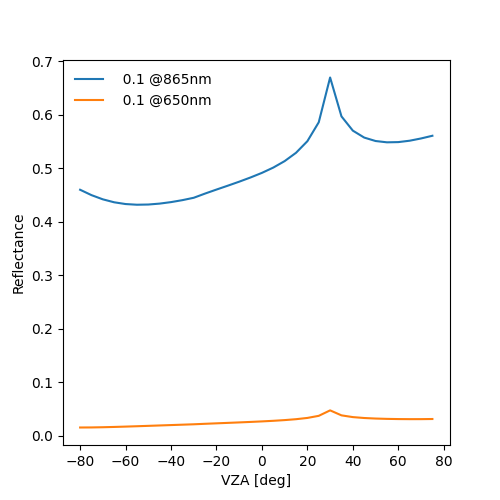

In [4]:
angular_gui()

<details>
<summary><i> Hint for question 3 </i> </summary>

<img src="./images/BRDF.png" width="400" alt="BRDF">

</details>




In [6]:
canopy_vi_exp_gui()


<a rel="license" href="http://creativecommons.org/licenses/by-nc/4.0/"><img alt="Creative Commons Licence" style="border-width:0" src="https://i.creativecommons.org/l/by-nc/4.0/88x31.png" /></a><br />This work is licensed under a <a rel="license" href="http://creativecommons.org/licenses/by-nc/4.0/">Creative Commons Attribution-NonCommercial 4.0 International License</a>.